# Meta-training a continuous-action update rule

Upload or clone **your modified continuous-action checkout** before running this notebook. Run from its repository root or `colabs` directory, or place it at `/content/disco_rl` in Colab. The installation cell never fetches unchanged upstream source; restart the kernel if an older `disco_rl` has already been imported. Meta-parameters start randomly: old Disco103 checkpoints are incompatible and are not downloaded.

Continuous Catch uses bounded scalar actions. The output named `logits` is now a bank of continuous action samples, not categorical logits. KDE approximates its density, policy gradient, entropy, and V-trace importance ratios: `num_samples` controls sample count and `kde_bandwidth` controls density smoothing. `wasserstein_smoothing` separately smooths the Wasserstein-1 target penalty. These finite-sample approximations depend on all three settings; they are not exact continuous distributions.

`y`, `z`, and Q return bins remain categorical. `z` has shape `[T, B, N, Z]`, while `z_a` has shape `[T, B, Z]` and predicts the **actual executed action**; `aux_pi_a` is its action-conditioned next-policy sample bank and `q_a` its categorical return prediction. Never index these with float actions. Rollouts retain `_policy_noise` and `_model_action` for faithful replay; network torsos (including the value network) ignore these internal fields and see only physical observations.

Defaults are a small CPU-oriented demonstration (two agents, two inner updates, explicitly configurable `num_steps`), not evidence of successful training. Setup does not train. The final optional smoke test performs one reward-only meta-update and checks numerical health; run it explicitly before a longer experiment.

In [1]:
# @title Install only the modified local checkout (run this cell yourself).

from pathlib import Path
import importlib
import subprocess
import sys

candidates = [Path.cwd(), Path.cwd().parent, Path('/content/disco_rl')]
repo_root = next((p.resolve() for p in candidates
                  if (p / 'disco_rl' / 'continuous_policies.py').is_file()
                  and ((p / 'pyproject.toml').is_file()
                       or (p / 'setup.py').is_file())), None)
if repo_root is None:
  raise RuntimeError(
      'Modified checkout unavailable. Upload/clone the continuous-action '
      'repository to /content/disco_rl, or run from its root or colabs '
      'directory. Do not install the unchanged upstream repository.')
if any(name == 'disco_rl' or name.startswith('disco_rl.')
       for name in sys.modules):
  raise RuntimeError('Restart the kernel, then run this local-install cell first.')
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-e', str(repo_root)])
sys.path.insert(0, str(repo_root))
importlib.invalidate_caches()
import disco_rl
if Path(disco_rl.__file__).resolve().parent != repo_root / 'disco_rl':
  raise RuntimeError('disco_rl did not resolve to the modified checkout; restart the kernel.')
print(f'Using modified source: {disco_rl.__file__}')

from typing import Any
from functools import partial

import chex
import distrax
import jax
import jax.numpy as jnp
from matplotlib import pyplot as plt
from ml_collections import config_dict
import numpy as np
import optax
import pandas as pd
import seaborn as sns
import tqdm

# Types & utils
from disco_rl import types
from disco_rl import utils
from disco_rl import continuous_policies

# Environments
from disco_rl.environments import base as base_env
from disco_rl.environments import jittable_envs

# Learning
from disco_rl import agent as agent_lib
from disco_rl.value_fns import value_fn

axis_name = 'i'  # for parallelisation

Using modified source: C:\Users\danielyates\dev\disco_rl\disco_rl\disco_rl\__init__.py


In [2]:
# @title Continuous-policy configuration (no pretrained checkpoint).

num_samples = 32
kde_bandwidth = 0.1
wasserstein_smoothing = 0.05
action_minimum = -1.0
action_maximum = 1.0
kde_kwargs = dict(bandwidth=kde_bandwidth,
                  minimum=action_minimum, maximum=action_maximum)
print(dict(num_samples=num_samples, **kde_kwargs,
           wasserstein_smoothing=wasserstein_smoothing))

{'num_samples': 32, 'bandwidth': 0.1, 'minimum': -1.0, 'maximum': 1.0, 'wasserstein_smoothing': 0.05}


In [3]:
# @title Configure a simple MLP agent.


def get_env(batch_size: int) -> base_env.Environment:
  return jittable_envs.ContinuousCatchJittableEnvironment(
      batch_size=batch_size,
      env_settings=jittable_envs.get_config_continuous_catch(),
  )


# Create a dummy environment.
env = get_env(batch_size=1)

# Create settings for an agent.
agent_settings = agent_lib.get_settings_disco(
    continuous_actions=True, num_samples=num_samples,
    kde_bandwidth=kde_bandwidth,
    wasserstein_smoothing=wasserstein_smoothing,
    action_minimum=action_minimum, action_maximum=action_maximum,
)
agent_settings.net_settings.name = 'mlp'
agent_settings.net_settings.net_args = dict(
    dense=(32, 32),
    model_arch_name='lstm',
    head_w_init_std=1e-2,
    model_kwargs=dict(
        head_mlp_hiddens=(32,),
        lstm_size=32,
    ),
)
agent_settings.learning_rate = 5e-4
agent_settings.update_rule.net.hidden_size = 32
agent_settings.update_rule.net.meta_rnn_kwargs.hidden_size = 32

# Create the agent.
agent = agent_lib.Agent(
    agent_settings=agent_settings,
    single_observation_spec=env.single_observation_spec(),
    single_action_spec=env.single_action_spec(),
    batch_axis_name=axis_name,
)

# This architecture requires newly initialized meta-parameters.
random_update_rule_params, _ = agent.update_rule.init_params(
    jax.random.PRNGKey(1)
)
print('Random continuous-action update rule initialized.')
print(dict(continuous_actions=agent_settings.update_rule.continuous_actions,
           num_samples=agent_settings.update_rule.num_samples,
           kde_bandwidth=agent_settings.update_rule.kde_bandwidth,
           wasserstein_smoothing=agent_settings.update_rule.wasserstein_smoothing))

Random continuous-action update rule initialized.
{'continuous_actions': True, 'num_samples': 32, 'kde_bandwidth': 0.1, 'wasserstein_smoothing': 0.05}


In [4]:
# @title Helper functions for interacting with environments.

def unroll_jittable_actor(
    params,
    actor_state,
    ts,
    env_state,
    rng,
    env,
    rollout_len,
    actor_step_fn,
):

  def _single_step(carry, step_rng):
    env_state, ts, actor_state = carry
    actor_timestep, actor_state = actor_step_fn(
        params, step_rng, ts, actor_state
    )
    env_state, ts = env.step(env_state, actor_timestep.actions)
    return (env_state, ts, actor_state), actor_timestep

  (env_state, ts, actor_state), actor_rollout = jax.lax.scan(
      _single_step,
      (env_state, ts, actor_state),
      jax.random.split(rng, rollout_len),
  )

  actor_rollout = types.ActorRollout.from_timestep(actor_rollout)
  return actor_rollout, actor_state, ts, env_state

In [5]:
# @title Meta training agent


@chex.dataclass
class MetaTrainState:
  learner_state: agent_lib.LearnerState
  actor_state: types.HaikuState
  value_state: types.ValueState
  env_state: Any
  env_timestep: types.EnvironmentTimestep


class MetaTrainAgent:
  """Meta training agent bundles together all meta training-related funct-ty."""

  agent: agent_lib.Agent
  value_fn: value_fn.ValueFunction
  env: base_env.Environment

  def __init__(
      self,
      batch_size_per_device: int,
      agent_settings: config_dict.ConfigDict,
      value_fn_config: types.ValueFnConfig,
      axis_name: str | None = axis_name,
  ):
    self.env = get_env(batch_size_per_device)
    self.batch_size_per_device = batch_size_per_device
    self.agent = agent_lib.Agent(
        agent_settings=agent_settings,
        single_observation_spec=self.env.single_observation_spec(),
        single_action_spec=self.env.single_action_spec(),
        batch_axis_name=axis_name,
    )
    self.value_fn = value_fn.ValueFunction(value_fn_config, axis_name=axis_name)
    self._unroll_jittable_actor = jax.jit(
        unroll_jittable_actor,
        static_argnames=('env', 'rollout_len', 'actor_step_fn'),
    )

  @property
  def learner_step(self):
    return self.agent.learner_step

  @property
  def actor_step(self):
    return self.agent.actor_step

  @property
  def unroll_net(self):
    return self.agent.unroll_net

  def init_state(self, rng_key: chex.PRNGKey) -> MetaTrainState:
    """Initialize the meta train state."""
    dummy_obs = utils.zeros_like_spec(
        self.env.single_observation_spec(),
        prepend_shape=(self.batch_size_per_device,),
    )
    rng_keys = jax.random.split(rng_key, 3)
    env_state, env_timestep = self.env.reset(rng_key)
    return MetaTrainState(
        learner_state=self.agent.initial_learner_state(rng_keys[0]),
        actor_state=self.agent.initial_actor_state(rng_keys[1]),
        value_state=self.value_fn.initial_state(rng_keys[2], dummy_obs),
        env_state=env_state,
        env_timestep=env_timestep,
    )

  def unroll_actor(
      self, state: MetaTrainState, rng: chex.PRNGKey, rollout_len: int
  ) -> tuple[MetaTrainState, types.ActorRollout]:
    """Unrolls the actor for the given number of steps and updates the state."""
    rollout, new_actor_state, new_env_timestep, new_env_state = (
        self._unroll_jittable_actor(
            state.learner_state.params,
            state.actor_state,
            state.env_timestep,
            state.env_state,
            rng,
            self.env,
            rollout_len,
            self.actor_step,
        )
    )
    new_state = MetaTrainState(
        learner_state=state.learner_state,
        actor_state=new_actor_state,
        value_state=state.value_state,
        env_state=new_env_state,
        env_timestep=new_env_timestep,
    )
    return new_state, rollout


In [6]:
# @title Calculate meta gradients for a single agent.


def calculate_meta_gradient(
    update_rule_params: types.MetaParams,
    agent_state: MetaTrainState,
    train_rollouts: types.ActorRollout,
    valid_rollout: types.ActorRollout,
    rng: chex.PRNGKey,
    agent: MetaTrainAgent,
    axis_name: str | None = axis_name,
    regularizer_scale: float = 1.0,
):
  """Calculates meta gradients for a single agent."""

  unroll_len = train_rollouts.rewards.shape[0]

  def _inner_step(carry, inputs):
    """Updates agent's and value fn's params using the current update rule."""
    update_rule_params, learner_state, actor_state, value_state = carry
    actor_rollout, learner_rng = inputs

    # Update agent's parameters.
    new_learner_state, new_actor_state, metrics = agent.learner_step(
        rng=learner_rng,
        rollout=actor_rollout,
        learner_state=learner_state,
        agent_net_state=actor_state,
        update_rule_params=update_rule_params,
        is_meta_training=True,
    )

    # Update value function.
    agent_out, _ = agent.unroll_net(
        learner_state.params, actor_state, actor_rollout
    )
    new_value_state, _, _ = agent.value_fn.update(
        value_state, actor_rollout, agent_out['logits']
    )

    return (
        update_rule_params,
        new_learner_state,
        new_actor_state,
        new_value_state,
    ), metrics

  def _outer_loss(
      update_rule_params: types.MetaParams,
      agent_state: MetaTrainState,
      train_rollouts: types.ActorRollout,
      valid_rollout: types.ActorRollout,
      rng: chex.PRNGKey,
  ):
    """Calculates (meta) loss for the update rule."""
    train_rng = rng

    # Perform N inner steps (i.e. agent's params' updates).
    learner_rngs = jax.random.split(train_rng, unroll_len)
    (_, new_learner_state, new_actor_state, new_value_state), train_metrics = (
        jax.lax.scan(
            _inner_step,
            (
                update_rule_params,
                agent_state.learner_state,
                agent_state.actor_state,
                agent_state.value_state,
            ),
            (train_rollouts, learner_rngs),
        )
    )
    train_meta_out = train_metrics.pop('meta_out')

    # Replay saved policy noise and executed model actions, including bootstrap.
    agent_out_on_valid, _ = agent.unroll_net(
        new_learner_state.params,
        valid_rollout.first_state(time_axis=0),
        valid_rollout,
    )

    # Calculate value_fn on the validation rollout.
    value_out, _, _, _ = agent.value_fn.get_value_outs(
        new_value_state, valid_rollout, agent_out_on_valid['logits']
    )
    actions_on_valid = valid_rollout.actions[:-1]
    samples_on_valid = agent_out_on_valid['logits'][:-1]
    adv_t = jax.lax.stop_gradient(value_out.normalized_adv)

    # Calculate meta loss' components.
    # Policy gradient loss.
    pg_loss_per_step = continuous_policies.kde_policy_gradient_loss(
        samples_on_valid, actions_on_valid, advantages=adv_t,
        backprop=False, **kde_kwargs,
    )

    # Meta regularizers.
    reg_loss = 0
    policy_entropy = continuous_policies.kde_entropy(
        samples_on_valid, **kde_kwargs
    ).mean()
    reg_loss += -1e-2 * policy_entropy

    # Validation regularisers.
    z_a = agent_out_on_valid['z_a'][:-1]
    y_entropy_loss = -jnp.mean(
        distrax.Softmax(agent_out_on_valid['y']).entropy()
    )
    z_entropy_loss = -jnp.mean(distrax.Softmax(z_a).entropy())
    reg_loss += 1e-3 * (y_entropy_loss + z_entropy_loss)

    # Train regularisers.
    dp, dy, dz = train_meta_out['pi'], train_meta_out['y'], train_meta_out['z']
    chex.assert_equal_shape_prefix([dp, dy, dz], 3)  # [N, T, B, ...]
    reg_loss += 1e-3 * jnp.mean(jnp.square(jnp.mean(dy, axis=(1, 2, 3))))
    reg_loss += 1e-3 * jnp.mean(jnp.square(jnp.mean(dz, axis=(1, 2, 3))))
    reg_loss += 1e-3 * jnp.mean(jnp.square(jnp.mean(dp, axis=(1, 2, 3))))
    target_samples = train_meta_out['target_out']['logits'][:, :-1]
    chex.assert_equal_shape([target_samples, dp])  # [inner, T, B, samples]
    target_w1 = continuous_policies.smooth_wasserstein_1(
        jax.lax.stop_gradient(target_samples), dp,
        smoothing=wasserstein_smoothing,
    )
    reg_loss += 1e-2 * jnp.mean(target_w1)
    reg_loss *= regularizer_scale

    # Meta loss.
    meta_loss = pg_loss_per_step.mean() + reg_loss

    # Update logs and states.
    meta_log = dict(
        adv=value_out.adv.mean(),
        normalized_adv=value_out.normalized_adv.mean(),
        validation_reward_abs=jnp.abs(valid_rollout.rewards[1:]).sum(),
        entropy=policy_entropy,
        y_entropy=-y_entropy_loss,
        z_entropy=-z_entropy_loss,
        target_w1=target_w1.mean(),
        value=value_out.value.mean(),
        val_importance_weight=jnp.mean(jnp.minimum(value_out.rho, 1.0)),
        meta_loss=meta_loss,
        pg_loss=pg_loss_per_step.mean(),
        reg_loss=reg_loss,
    )
    new_agent_state = MetaTrainState(
        learner_state=new_learner_state,
        actor_state=new_actor_state,
        value_state=new_value_state,
        env_state=agent_state.env_state,
        env_timestep=agent_state.env_timestep,
    )

    return meta_loss, (new_agent_state, train_metrics, meta_log)

  # Calculate meta gradients.
  meta_grads, outputs = jax.grad(_outer_loss, has_aux=True)(
      update_rule_params, agent_state, train_rollouts, valid_rollout, rng
  )
  new_agent_state, train_metrics, meta_log = outputs
  if axis_name is not None:
    (meta_grads, train_metrics, meta_log) = jax.lax.pmean(
        (meta_grads, train_metrics, meta_log), axis_name
    )

  return meta_grads, (new_agent_state, train_metrics, meta_log)

In [7]:
# @title Meta update step (requires calculating meta gradients for all agents).


def meta_update(
    update_rule_params: types.MetaParams,
    meta_opt_state: optax.OptState,
    agents_states: list[MetaTrainState],
    rng: chex.PRNGKey,
    axis_name: str | None = axis_name,
    regularizer_scale: float = 1.0,
):
  """Calculates an update for the meta parameters."""

  # Generate `num_inner_steps` trajectories for each of `num_agents` agents.
  train_rollouts = [None] * num_agents
  valid_rollouts = [None] * num_agents
  rng_act, rng_upd = jax.random.split(rng)
  rngs_per_agent_act = jax.random.split(rng_act, num_agents)
  for agent_i in range(num_agents):
    agent, state = agents[agent_i], agents_states[agent_i]
    rollouts = [None] * num_inner_steps
    rngs_per_step = jax.random.split(
        rngs_per_agent_act[agent_i], num_inner_steps + 1
    )
    for step_i in range(num_inner_steps):
      state, rollouts[step_i] = agent.unroll_actor(
          state, rngs_per_step[step_i], rollout_len
      )
    train_rollouts[agent_i] = utils.tree_stack(rollouts)

    # Generate 2x longer trajectories for validation.
    agents_states[agent_i], valid_rollouts[agent_i] = agent.unroll_actor(
        state, rngs_per_step[-1], 2 * rollout_len
    )

  # Calculate meta gradients for each agent.
  meta_grads = [None] * num_agents
  rngs_per_agent_upd = jax.random.split(rng_upd, num_agents)
  metrics_per_agent, logs_per_agent = [], []
  for agent_i in range(num_agents):
    meta_grads[agent_i], (agents_states[agent_i], metrics, meta_log) = (
        calculate_meta_gradient(
            update_rule_params=update_rule_params,
            agent_state=agents_states[agent_i],
            train_rollouts=train_rollouts[agent_i],
            valid_rollout=valid_rollouts[agent_i],
            rng=rngs_per_agent_upd[agent_i],
            agent=agents[agent_i],
            axis_name=axis_name,
            regularizer_scale=regularizer_scale,
        )
    )
    metrics_per_agent.append(metrics)
    logs_per_agent.append(meta_log)
  metrics = jax.tree.map(lambda x: x.mean(0), utils.tree_stack(metrics_per_agent))
  meta_log = jax.tree.map(lambda x: x.mean(0), utils.tree_stack(logs_per_agent))

  # Log rewards and proportion positive rewards.
  rewards = [None] * num_agents
  pos_rewards = [None] * num_agents
  neg_rewards = [None] * num_agents
  for agent_i in range(num_agents):
    assert train_rollouts[agent_i] is not None
    r = train_rollouts[agent_i].rewards
    rewards[agent_i] = r.mean()

    pos_rewards[agent_i] = (r > 0).sum()
    neg_rewards[agent_i] = (r < 0).sum()

  # Average meta gradients across all agents and pass through meta optimizer.
  # Note that we had a separate meta optimiser for each agent in the original
  # work; that logic is omitted here for simplicity.
  avg_meta_gradient = jax.tree.map(
      lambda x: x.mean(axis=0), utils.tree_stack(meta_grads)
  )
  meta_update, meta_opt_state = meta_opt.update(
      avg_meta_gradient, meta_opt_state
  )
  update_rule_params = optax.apply_updates(update_rule_params, meta_update)

  meta_log['meta_grad_norm'] = optax.global_norm(avg_meta_gradient)
  meta_log['meta_up_norm'] = optax.global_norm(meta_update)
  meta_log['rewards'] = utils.tree_stack(rewards).mean()
  meta_log['pos_rewards'] = utils.tree_stack(pos_rewards).mean()
  meta_log['neg_rewards'] = utils.tree_stack(neg_rewards).mean()
  return update_rule_params, meta_opt_state, agents_states, metrics, meta_log

In [8]:
# @title Meta training config

num_steps = 500  # Increase explicitly for an actual training experiment.
num_agents = 2
rollout_len = 8  # Includes the final bootstrap timestep; keep >= 2.
num_inner_steps = 4
batch_size_per_device = 2
rng_key = jax.random.PRNGKey(4)

value_fn_config = types.ValueFnConfig(
    net='mlp',
    net_args=dict(
        dense=(32, 32),
        head_w_init_std=1e-2,
        action_spec=(),
    ),
    learning_rate=1e-3,
    max_abs_update=1.0,
    discount_factor=0.99,
    td_lambda=0.96,
    outer_value_cost=1.0,
    continuous_actions=True,
    kde_bandwidth=kde_bandwidth,
    action_minimum=action_minimum,
    action_maximum=action_maximum,
)

# Use random params for the update rule.
update_rule_params = random_update_rule_params
meta_opt = optax.adam(learning_rate=5e-4)

meta_opt_state = meta_opt.init(update_rule_params)
meta_log = {}
metrics = {}

# Create multiple agents.
agents = []
agents_states = []
rng, rng_key = jax.random.split(rng_key)
for rng_key in jax.random.split(rng_key, num_agents):
  agents.append(
      MetaTrainAgent(
          batch_size_per_device=batch_size_per_device,
          agent_settings=agent_settings,
          value_fn_config=value_fn_config,
      )
  )
  agents_states.append(agents[-1].init_state(rng_key))

# Parallelise using all available devices.
devices = jax.devices()
jitted_meta_update = jax.pmap(meta_update, axis_name=axis_name, devices=devices)

In [9]:
# @title Run meta-training (note that compilation can take time!).

# Replicate parameters for each device.
step_update_rule_params = jax.device_put_replicated(
    update_rule_params, devices
)
step_meta_opt_state = jax.device_put_replicated(meta_opt_state, devices)
step_agents_states = jax.device_put_replicated(agents_states, devices)

# Run the meta learning loop.
for meta_step in tqdm.tqdm(range(num_steps)):
  if meta_step in metrics:  # to support interrupting and continuing
    continue

  rng, step_rngs = jax.random.split(rng)
  step_rngs = jax.random.split(step_rngs, len(devices))
  (
      step_update_rule_params,
      step_meta_opt_state,
      step_agents_states,
      metrics[meta_step],
      meta_log[meta_step],
  ) = jitted_meta_update(
      update_rule_params=step_update_rule_params,
      meta_opt_state=step_meta_opt_state,
      agents_states=step_agents_states,
      rng=step_rngs,
  )
  metrics[meta_step], meta_log[meta_step] = jax.device_get(
      (metrics[meta_step], meta_log[meta_step])
  )

# Collect metrics from all devices.
metrics, meta_log = utils.gather_from_devices((metrics, meta_log))
metrics, meta_log = jax.tree.map(lambda x: x.mean(0), (metrics, meta_log))

100%|██████████| 500/500 [11:12<00:00,  1.35s/it]  


In [10]:
# @title Process logs and metrics.

meta_log_cpu = jax.device_get(meta_log)
steps = np.sort(np.unique(list(meta_log_cpu.keys())))
rows = []
for i in steps:
  for key in (
      'meta_grad_norm',
      'meta_up_norm',
      'meta_loss',
      'pg_loss',
      'entropy',
      'target_w1',
      'rewards',
      'pos_rewards',
      'neg_rewards',
  ):
    rows.append(dict(step=i, value=float(meta_log_cpu[i][key]), f=key))

df = pd.DataFrame(rows)

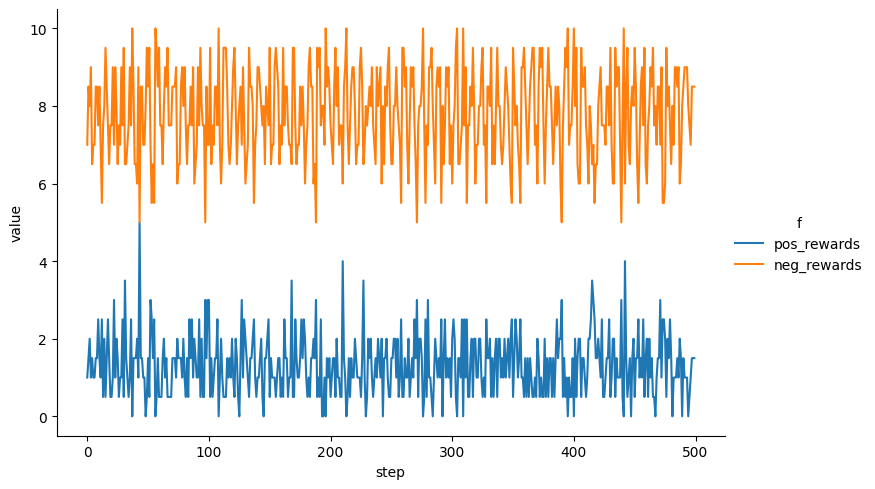

In [11]:
sns.relplot(
    data=df[df.f.isin(['pos_rewards', 'neg_rewards'])],
    x='step',
    y='value',
    kind='line',
    hue='f',
    errorbar=None,
    aspect=1.5,
)
plt.show()

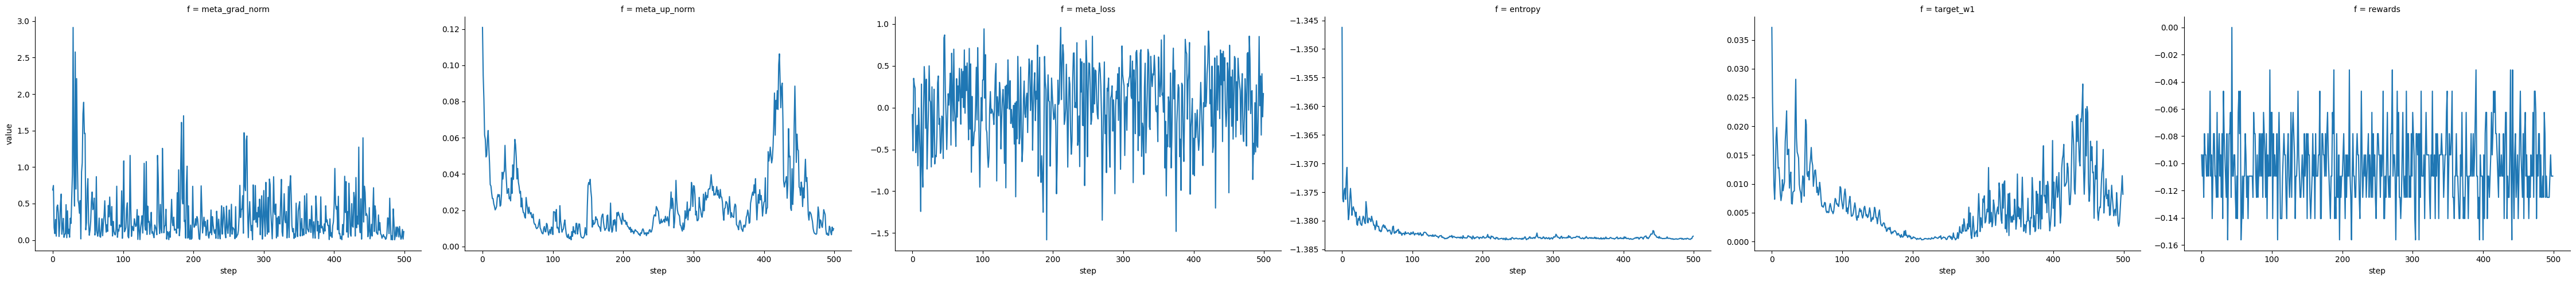

In [12]:
sns.relplot(
    data=df[
        df.f.isin(['meta_grad_norm', 'meta_loss', 'meta_up_norm', 'rewards',
                   'entropy', 'target_w1'])
    ],
    x='step',
    y='value',
    kind='line',
    col='f',
    errorbar=None,
    aspect=1.5,
    facet_kws={'sharey': False, 'sharex': True},
)
plt.show()

In [13]:
# @title Optional one-update smoke test (run after config; no training claim).

def run_optional_smoke_test(seed=17):
  # Disable every regularizer so a nonzero gradient must come from PG.
  reward_only_update = jax.pmap(
      partial(meta_update, regularizer_scale=0.0),
      axis_name=axis_name, devices=devices,
  )
  initial_params = jax.device_put_replicated(update_rule_params, devices)
  result = reward_only_update(
      update_rule_params=initial_params,
      meta_opt_state=jax.device_put_replicated(meta_opt_state, devices),
      agents_states=jax.device_put_replicated(agents_states, devices),
      rng=jax.random.split(jax.random.PRNGKey(seed), len(devices)),
  )
  result = jax.device_get(result)  # Synchronize compilation and execution.
  for leaf in jax.tree.leaves(result):
    if not np.all(np.isfinite(np.asarray(leaf))):
      raise AssertionError('Nonfinite smoke-test state, metric, or update.')
  smoke_log = result[-1]
  if not np.all(smoke_log['validation_reward_abs'] > 0):
    raise AssertionError(
        'No validation reward signal. Increase rollout_len or try another seed; '
        'this run cannot establish a reward-driven meta-gradient.')
  if not np.all(smoke_log['meta_grad_norm'] > 0):
    raise AssertionError('Reward-only meta-gradient is zero; inspect the inner update path.')
  delta = jax.tree.map(lambda a, b: a - b, result[0], initial_params)
  if not float(optax.global_norm(delta)) > 0:
    raise AssertionError('Meta-parameters did not change.')
  print('One reward-only meta-update is finite with a nonzero meta-gradient.')
  return smoke_log

RUN_SMOKE_TEST = False  # Opt in explicitly; does not overwrite training state.
if RUN_SMOKE_TEST:
  smoke_log = run_optional_smoke_test()
